# 7. 머신러닝 데이터 분석

## 1. 머신러닝 개요

## 1-1 머신러닝이란?

- 기계 스스로 데이터를 학습하여 서로 다른 변수간의 관계를 찾아나가는 과정
- 해결하려는 문제에 따라 예측, 분류, 군집 알고리즘 등으로 분류됨

## 1-2 지도학습 vs 비지도 학습

- 지도학습: 정답데이터를 다른 데이터와 함께 컴퓨터 알고리즘에 입력 / 회귀분석, 분류
- 비지도학습: 정답 데이터 없이 컴퓨터 알고리즘 스스로 데이터로부터 숨은 패턴을 찾아내는 방식 / 군집분석

## 1-3 머신러닝 프로세스

- 머신러닝 데이터 분석 시작 전에 컴퓨터알고리즘이 이해할 수 있는 형태로 데이터를 변환하는 작업이 선행되어야 함
- 이후에는 여러 속성 간의 관계를 분석하여 결과를 예측하는 모형을 학습을 통해 찾음
- train data: 모형학습에 사용하는 데이터
- test data: 학습을 마친 모형의 예측 능력을 평가하기 위한 데이터

## 2 회귀분석

- 가격, 매출, 주가, 환율, 수량 등 연속적인 값을 갖는 연속변수를 예측하는데 주로 활용
- 종속변수 or 예측변수: 분석모형이 예측하고자 하는 목표
- 독립변수 or 설명변수: 예측을 위해 모형이 사용하는 속성

## 2-1 단순회귀분석

- 독립변수 x가 종속변수 y에 영향을 준다면 두 변수 사이에 선형관계가 있다고 이야기함
- 선형관계를 알고 있다면 새로운 독립변수 x가 주어졌을 때 거기에 대응되는 종속변수 y값을 예측 가능
- 단순회귀분석: 두 변수 사이에 일대일로 대응되는 확률적, 통계적 상관성을 찾는 알고리즘
- Y=aX+b : 종속변수 y와 독립변수 x사이의 관계
- 단순회귀분석 알고리즘은 훈련데이터를 이용하여 a와 직선이 y축과 교차하는 지점인 b를 반복학습을 통해 찾음
- 변수 x와 y에 대한 정보를 가지고 일차방정식의 계수 a, b를 찾는 과정

In [1]:
# 예제 7-1: 단순회귀분석

from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# [Step 1] 데이터 준비 - 자돈차 연비 데이터셋 가져오기

# 1. 구글 드라이브 마운트
drive.mount('/content/drive')

# 2. CSV 파일 경로
file_path = "/content/drive/MyDrive/[980-8]예제파일_파이썬 머신러닝 판다스 데이터 분석(개정판)/pandas-data-analysis-main/part7/data/auto-mpg.csv"

# 3. 데이터 불러오기
df = pd.read_csv(file_path, header=None)

df.columns = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
              'acceleration', 'model year', 'origin', 'name']

print(df.head())
print("\n")
print("------------------------------------------------")
print("\n")

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 10)
print(df.head())
print("\n")
print("------------------------------------------------")
print("\n")


Mounted at /content/drive
    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0      130.0  3504.0          12.0          70   
1  15.0          8         350.0      165.0  3693.0          11.5          70   
2  18.0          8         318.0      150.0  3436.0          11.0          70   
3  16.0          8         304.0      150.0  3433.0          12.0          70   
4  17.0          8         302.0      140.0  3449.0          10.5          70   

   origin                       name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  


------------------------------------------------


    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0      130.0  3504.0          12.0          70   
1  15.0          8         350.0      

In [2]:
# [Step 2] 데이터 탐색

# 데이터 자료형 확인
print(df.info())
print("\n")
print("------------------------------------------------")
print("\n")

# 데이터 통계 요약 정보 확인
print(df.describe())
print("\n")
print("------------------------------------------------")
print("\n")

# horsepower 열의 자료형 변경(문자열 -> 숫자)
print(df['horsepower'].unique())   # horsepower 열의 고유값 확인
print("\n")
print("------------------------------------------------")
print("\n")

# '?'을 결측값으로 변경
df['horsepower'] = df['horsepower'].replace('?', np.nan)

# 결측값 제거
df.dropna(subset=['horsepower'], inplace=True)

# 실수형으로 변환
df['horsepower'] = df['horsepower'].astype(float)

print(df.describe())
print("\n")
print("------------------------------------------------")
print("\n")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB
None


------------------------------------------------


              mpg   cylinders  displacement       weight  acceleration  \
count  398.000000  398.000000    398.000000   398.000000    398.000000   
mean    23.514573    5.454774    193.425879  2970.424623     15.568090   
std      7.815984    1.701004    104.269838   846.841774      2.757689   
min   

    mpg  cylinders  horsepower  weight
0  18.0          8       130.0  3504.0
1  15.0          8       165.0  3693.0
2  18.0          8       150.0  3436.0
3  16.0          8       150.0  3433.0
4  17.0          8       140.0  3449.0


------------------------------------------------




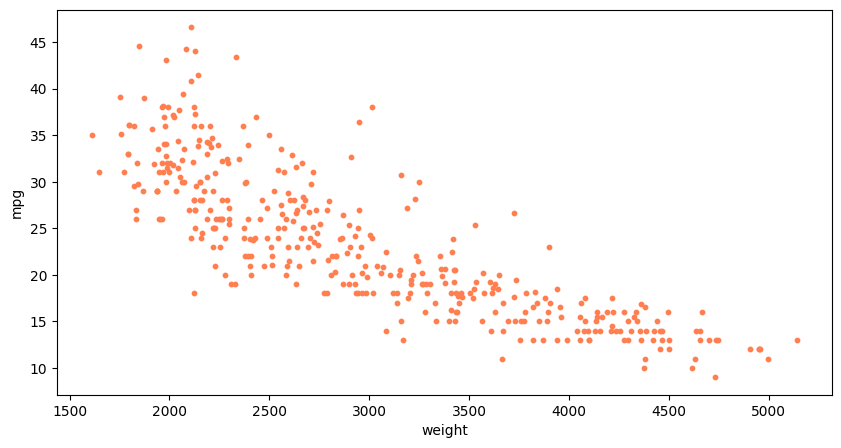

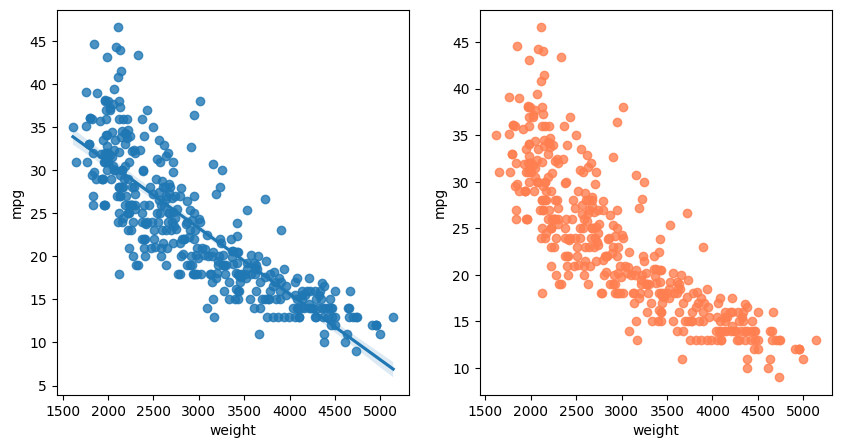

In [3]:
# [Step 3] 속성 선택

# 분석에 활용할 열(속성) 선택(연비, 실린더, 출력, 중량)
ndf = df[['mpg', 'cylinders', 'horsepower', 'weight']]
print(ndf.head())
print("\n")
print("------------------------------------------------")
print("\n")

### 종속 변수 y인 연비(mpg)와 다른 변수 간의 선형관계를 그래프로 확인
# Matplotlib으로 산점도 그리기
ndf.plot(kind='scatter', x='weight', y='mpg', c='coral', s=10, figsize=(10, 5))
plt.show()

# seaborn으로 산점도 그리기
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)

# 회귀선 표시
sns.regplot(x='weight', y='mpg', data=ndf, ax=ax1)
# 회귀선 미표시
sns.regplot(x='weight', y='mpg', data=ndf, ax=ax2, fit_reg=False, color='coral')
plt.show()
plt.close()



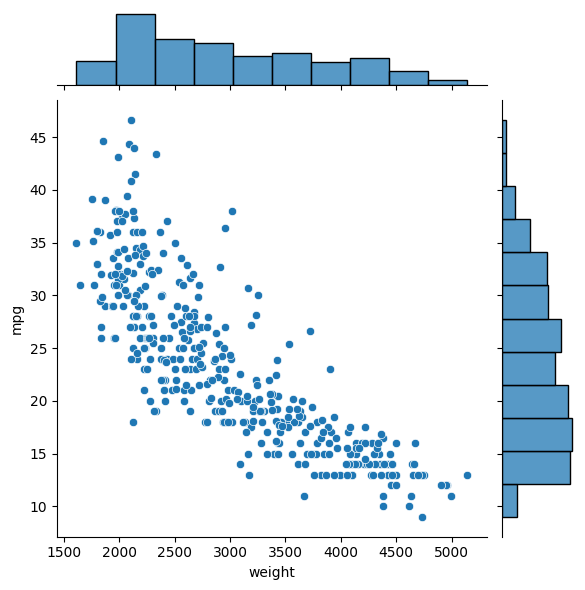

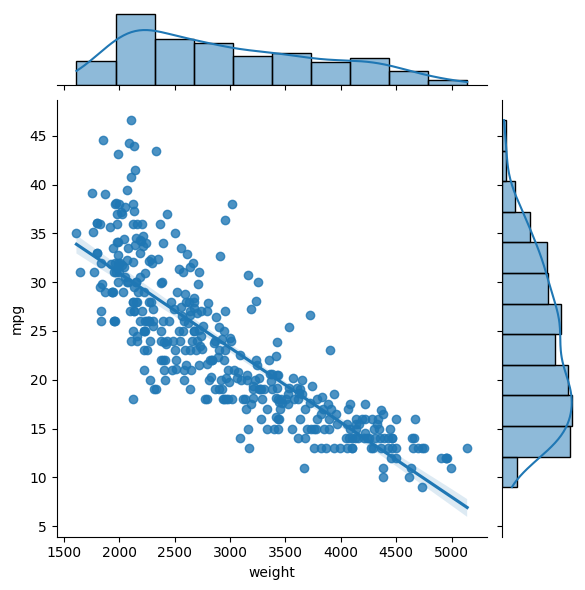

In [4]:
# seaborn 조인트 그래프 - 산점도, 히스토그램

sns.jointplot(x='weight', y='mpg', data=ndf)
sns.jointplot(x='weight', y='mpg', kind='reg', data=ndf)
plt.show()
plt.close()

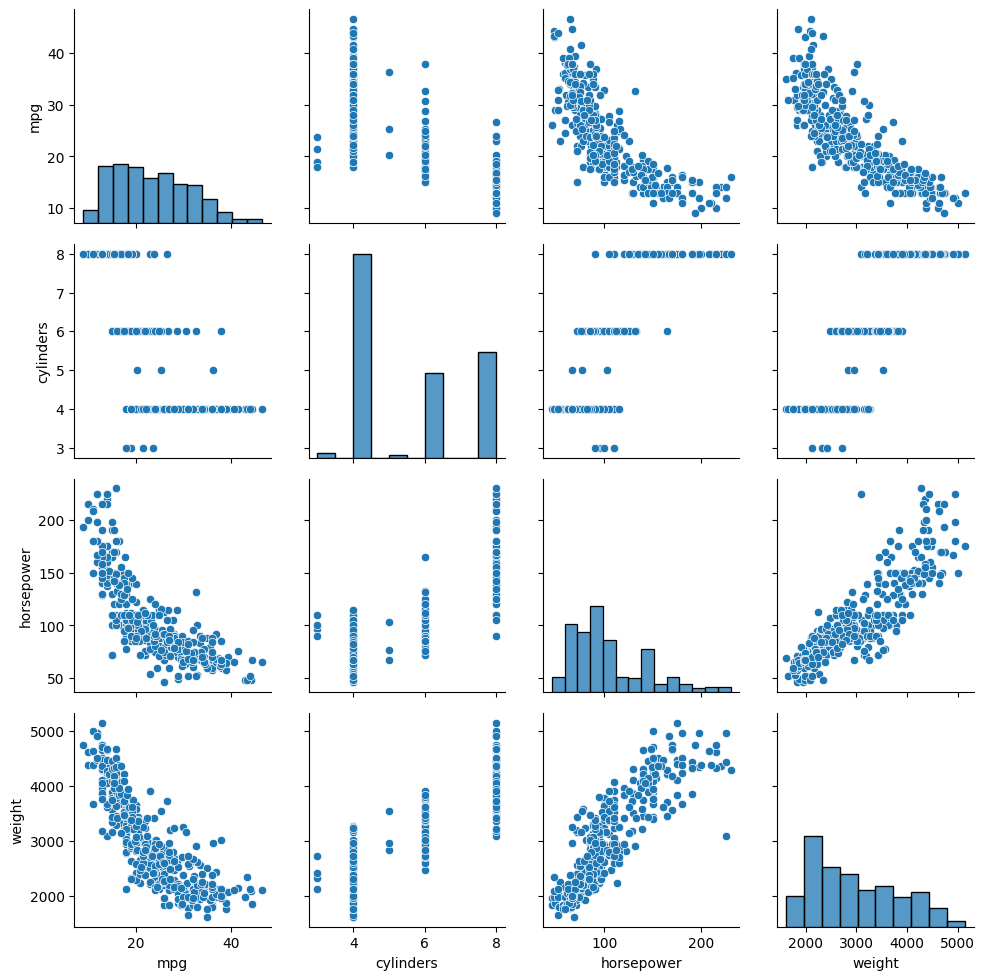

In [5]:
# seaborn pariplot으로 두 변수 간의 모든 경우의 수 그리기

ndf = df[['mpg', 'cylinders', 'horsepower', 'weight']]

grid_ndf = sns.PairGrid(ndf)

# 대각선에는 히스토그램
grid_ndf.map_diag(sns.histplot)

# 대각선 이외에는 산점도
grid_ndf.map_offdiag(sns.scatterplot)

plt.show()
plt.close()

In [6]:
# [Step 4] 훈련/검증 데이터 분할

# mpg열과 선형관계를 보이는 horsepower열과 weight 열을 독립변수 x로 선택하는 것을 고려
# train data와 test data로 나눠서 모형 구축, 7:3 비율

# 속성(변수) 선택

X = ndf[['weight']]   # 독립변수 x
Y = ndf['mpg']    # 종속변수 y

# 훈련 데이터와 테스트 데이터로 분할(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,    # 독립변수
                                                    Y,    # 종속변수
                                                    test_size=0.3,   # 검증 30%
                                                    random_state=10)    # 랜덤추출값

print('train data 개수 : ', len(X_train))
print('test data 개수 : ', len(X_test))

train data 개수 :  274
test data 개수 :  118


0.6822458558299322


기울기 a:  [-0.00775343]


y절편 b 46.7103662572801




/tmp/ipykernel_4933/2349538304.py:33: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax1 = sns.distplot(Y, hist=False, label="y")
/tmp/ipykernel_4933/2349538304.py:34: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax2 = sns.distplot(y_hat, hist=False, label="y_hat", ax=ax1)


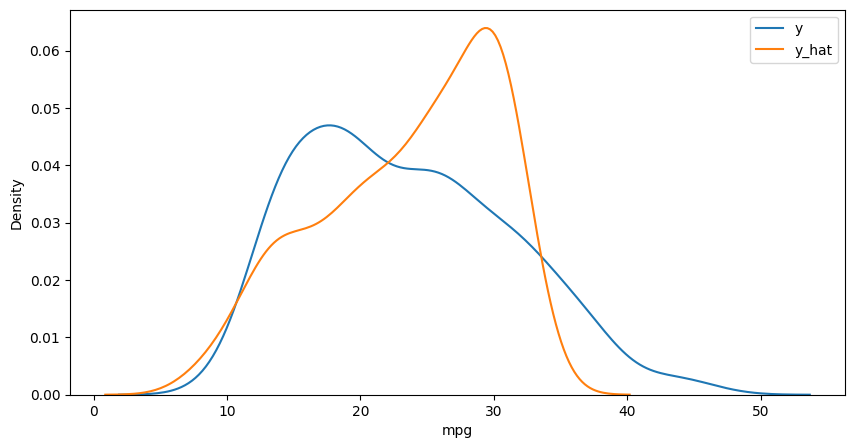

In [7]:
# [Step 5] 단순회귀분석 모형 만들기 - sklearn 사용

# LinearRegression() 함수로 회귀분석 모형 객체를 생성해서 변수 lr에 저장
# 모형 객체 lr에 fit() 메소드를 적용하고 훈련데이터를 전달하면 모형이 학습을 통해 회귀방정식의 계수 a,b를 찾음
# 학습을 마친 모형의 예측 능력을 평가하기 위해 검증데이터를 score() 메소드에 전달하여 lr모형의 결정계수(R-제곱)을 구함
# 결정계수의 값이 클수록 모형의 예측이 좋다고 판단함

# sklearn 라이브러리에서 선형회귀분석 모듈 가져오기
from sklearn.linear_model import LinearRegression

# 단순회귀분석 모형 객체 생성
lr = LinearRegression()
# train data를 가지고 모형 학습
lr.fit(X_train, Y_train)

# 학습을 마친 모형에 test data를 적용하여 결정계수(R-제곱) 계산
r_square = lr.score(X_test, Y_test)
print(r_square)
print("\n")

# 회귀식의 기울기
print('기울기 a: ', lr.coef_)
print("\n")

# 회귀식의 y절편
print('y절편 b', lr.intercept_)
print("\n")

# 모형에 전체 x 데이터를 입력하여 예측한 값 y_hat을 실제 y와 비교
y_hat = lr.predict(X)

plt.figure(figsize=(10, 5))
ax1 = sns.distplot(Y, hist=False, label="y")
ax2 = sns.distplot(y_hat, hist=False, label="y_hat", ax=ax1)
plt.legend()
plt.show()
plt.close()

### 출력된 결과를 보면 실제값은 왼쪽으로 편향되어있고 예측값은 반대로 오른쪽으로 편중되어있음 -> 독립변수 weight와 종속변수 mpg 사이에 선형관계가 있지만, 모형의 오차를 더 줄일 필요가 있어보임.
### 앞에서 그린 산점도를 보면 직선보다는 곡선의 형태가 더 적합해보임 -> 비선형 회귀분석을 통해 모형의 정확도 높일 수 있을 것

## 2-2 다항회귀분석

- 2차함수 이상의 다항함수를 이용하여 두 변수 간의 선형관계를 설명하는 알고리즘
- ex) 2차 함수는 X와 Y 관계를 Y =aX^2 + bX + c로 표시
- 다항회귀분석 모형은 학습을 통해 3개의 계수를 찾아 모형 완성

In [8]:
# 예제 7-2: 다항회귀분석

from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# [Step 1] 데이터 준비 - 자돈차 연비 데이터셋 가져오기

# 1. 구글 드라이브 마운트
drive.mount('/content/drive')

# 2. CSV 파일 경로
file_path = "/content/drive/MyDrive/[980-8]예제파일_파이썬 머신러닝 판다스 데이터 분석(개정판)/pandas-data-analysis-main/part7/data/auto-mpg.csv"

# 3. 데이터 불러오기
df = pd.read_csv(file_path, header=None)

df.columns = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
              'acceleration', 'model year', 'origin', 'name']

print(df.head())
print("\n")
print("------------------------------------------------")
print("\n")

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 10)
print(df.head())
print("\n")
print("------------------------------------------------")
print("\n")

# horsepower 열의 자료형 변경(문자열 -> 숫자)
print(df['horsepower'].unique())   # horsepower 열의 고유값 확인
print("\n")
print("------------------------------------------------")
print("\n")

# '?'을 결측값으로 변경
df['horsepower'] = df['horsepower'].replace('?', np.nan)

# 결측값 제거
df.dropna(subset=['horsepower'], inplace=True)

# 실수형으로 변환
df['horsepower'] = df['horsepower'].astype(float)

# 분석에 활용할 열(속성) 선택(연비, 실린더, 출력, 중량)
ndf = df[['mpg', 'cylinders', 'horsepower', 'weight']]

# ndf 데이터를 train data와 test data로 구분(7:3 비율)
X = ndf[['weight']]   # 독립변수 X
y = ndf['mpg']    # 종속변수 Y

# 훈련 데이터와 테스트 데이터로 분할(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data : ', X_train.shape)
print('test data : ', X_test.shape)
print("\n")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0      130.0  3504.0          12.0          70   
1  15.0          8         350.0      165.0  3693.0          11.5          70   
2  18.0          8         318.0      150.0  3436.0          11.0          70   
3  16.0          8         304.0      150.0  3433.0          12.0          70   
4  17.0          8         302.0      140.0  3449.0          10.5          70   

   origin                       name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  


------------------------------------------------


    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0         

In [9]:
# [step 5] 비선형회귀분석 모형 -sklearn 사용

# sklearn 라이브러리에서 필요한 모듈 가져오기
from sklearn.linear_model import LinearRegression   # 선형회귀분석
from sklearn.preprocessing import PolynomialFeatures   # 다항식 변환

# 다항식으로 변환해서 2차식에 맞게 변환
poly = PolynomialFeatures(degree=2)   # 2차항 적용
X_train_poly = poly.fit_transform(X_train)   # X_train 데이터를 2차항으로 변형

print('원 데이터: ', X_train.shape)
print('2차항 변형 데이터: ', X_train_poly.shape)
print("\n")

원 데이터:  (274, 1)
2차항 변형 데이터:  (274, 3)




In [10]:
# train data를 가지고 모형 연습
pr = LinearRegression()
pr.fit(X_train_poly, y_train)

# 학습을 마친 모형에 test data를 적용하여 결정계수(R-제곱) 계산
X_test_poly = poly.fit_transform(X_test)   # X_test 데이터를 2차항으로 변형
r_square = pr.score(X_test_poly, y_test)
print(r_square)
print("\n")

0.708700926297548




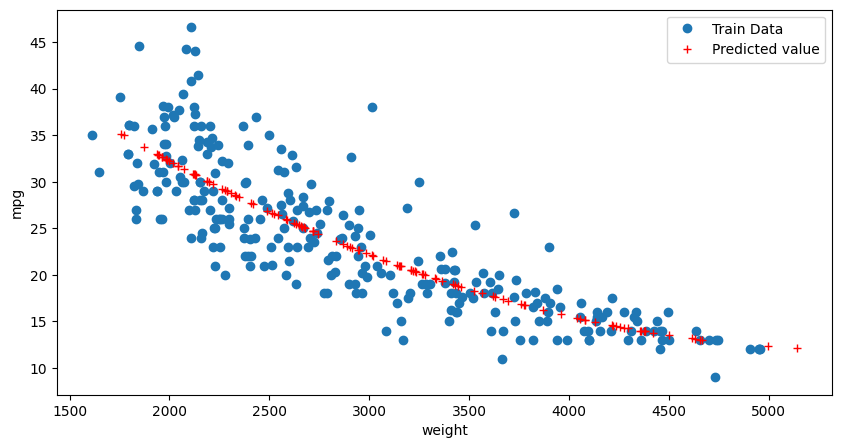

In [11]:
# train data의 산점도와 test data로 예측한 회귀선을 그래프로 출력
y_hat_test = pr.predict(X_test_poly)

fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(1, 1, 1)
ax.plot(X_train, y_train, 'o', label='Train Data')   # 데이터 분포
ax.plot(X_test, y_hat_test, 'r+', label='Predicted value')   # 모형이 학습한 회귀선
ax.legend(loc='best')
plt.xlabel('weight')
plt.ylabel('mpg')
plt.show()
plt.close()

### 모형의 결정계수가 높아진 것에서 알 수 있듯이 직선으로 표시된 단순회귀분석에 비해 데이터 패턴을 더욱 잘 설명한다고 말할 수 있다

/tmp/ipykernel_4933/21449090.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax1 = sns.distplot(y, hist=False, label='y')
/tmp/ipykernel_4933/21449090.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax2 = sns.distplot(y_hat, hist=False, label='y_hat', ax=ax1)


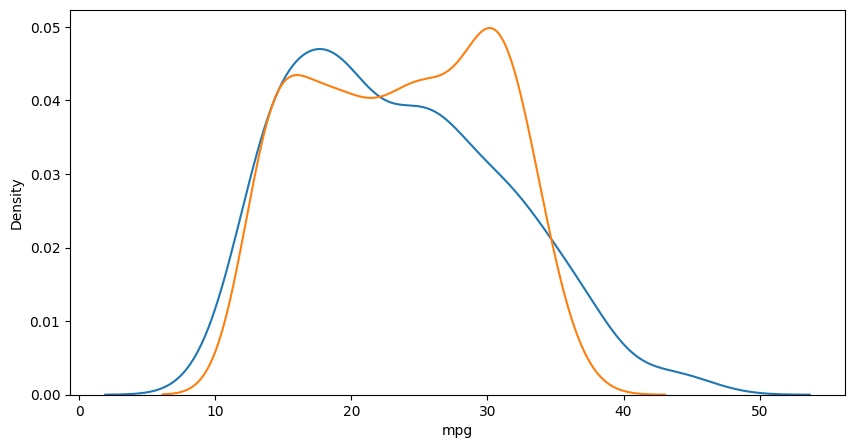

In [12]:
# 모형에 전체 X 데이터를 입력하여 예측한 값 y_hat을 실제 y와 비교
X_poly =  poly.fit_transform(X)
y_hat = pr.predict(X_poly)

plt.figure(figsize=(10, 5))
ax1 = sns.distplot(y, hist=False, label='y')
ax2 = sns.distplot(y_hat, hist=False, label='y_hat', ax=ax1)
plt.show()
plt.close()

### 앞의 단순회귀분석 결과보다 어느 한쪽으로 데이터가 편향되는 경향이 감소함 -> 더 적합한 모형

## 2-3 다중회귀분석

- 종속변수 Y에 영향을 주는 독립변수 X가 여러개인 경우 사용
- 다중회귀분석 알고리즘은 각 독립변수의 계수와 상수항에 적절한 값을 찾아서 모형 완성
- 모형의 예측값인 종속변수에 대한 실제 데이터를 알고 있는 상태에서 학습하기 때문에 지도학습으로 분류

In [13]:
# 예제 7-3: 다중회귀분석

from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# [Step 1] 데이터 준비 - 자돈차 연비 데이터셋 가져오기

# 1. 구글 드라이브 마운트
drive.mount('/content/drive')

# 2. CSV 파일 경로
file_path = "/content/drive/MyDrive/[980-8]예제파일_파이썬 머신러닝 판다스 데이터 분석(개정판)/pandas-data-analysis-main/part7/data/auto-mpg.csv"

# 3. 데이터 불러오기
df = pd.read_csv(file_path, header=None)

df.columns = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
              'acceleration', 'model year', 'origin', 'name']

print(df.head())
print("\n")
print("------------------------------------------------")
print("\n")

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 10)
print(df.head())
print("\n")
print("------------------------------------------------")
print("\n")

# horsepower 열의 자료형 변경(문자열 -> 숫자)
print(df['horsepower'].unique())   # horsepower 열의 고유값 확인
print("\n")
print("------------------------------------------------")
print("\n")

# '?'을 결측값으로 변경
df['horsepower'] = df['horsepower'].replace('?', np.nan)

# 결측값 제거
df.dropna(subset=['horsepower'], inplace=True)

# 실수형으로 변환
df['horsepower'] = df['horsepower'].astype(float)

# 분석에 활용할 열(속성) 선택(연비, 실린더, 출력, 중량)
ndf = df[['mpg', 'cylinders', 'horsepower', 'weight']]

# ndf 데이터를 train data와 test data로 구분(7:3 비율)
X = ndf[['cylinders', 'horsepower', 'weight']]   # 독립변수 X
y = ndf['mpg']    # 종속변수 Y

# 훈련 데이터와 테스트 데이터로 분할(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data : ', X_train.shape)
print('test data : ', X_test.shape)
print("\n")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0      130.0  3504.0          12.0          70   
1  15.0          8         350.0      165.0  3693.0          11.5          70   
2  18.0          8         318.0      150.0  3436.0          11.0          70   
3  16.0          8         304.0      150.0  3433.0          12.0          70   
4  17.0          8         302.0      140.0  3449.0          10.5          70   

   origin                       name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  


------------------------------------------------


    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0         

In [14]:
# [step 5] 단순회귀분석 모형 -sklearn 사용

# sklearn 라이브러리에서 필요한 모듈 가져오기
from sklearn.linear_model import LinearRegression   # 선형회귀분석

# 단순회귀분석 모형 객체 생성
lr = LinearRegression()
# train data를 가지고 모형 학습
lr.fit(X_train, y_train)

# 학습을 마친 모형에 test data를 적용하여 결정계수 계산
r_square = lr.score(X_test, y_test)
print(r_square)
print("\n")

# 회귀식의 기울기
print('X 변수의 계수 a: ', lr.coef_)
print("\n")

# 회귀식의 y절편
print('상수항 b: ', lr.intercept_)
print("\n")

0.6939048496695599


X 변수의 계수 a:  [-0.60691288 -0.03714088 -0.00522268]


상수항 b:  46.414351269634025




/tmp/ipykernel_4933/2714610171.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax1 = sns.distplot(y_test, hist=False, label='y_test')
/tmp/ipykernel_4933/2714610171.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax2 = sns.distplot(y_hat, hist=False, label='y_hat', ax=ax1)


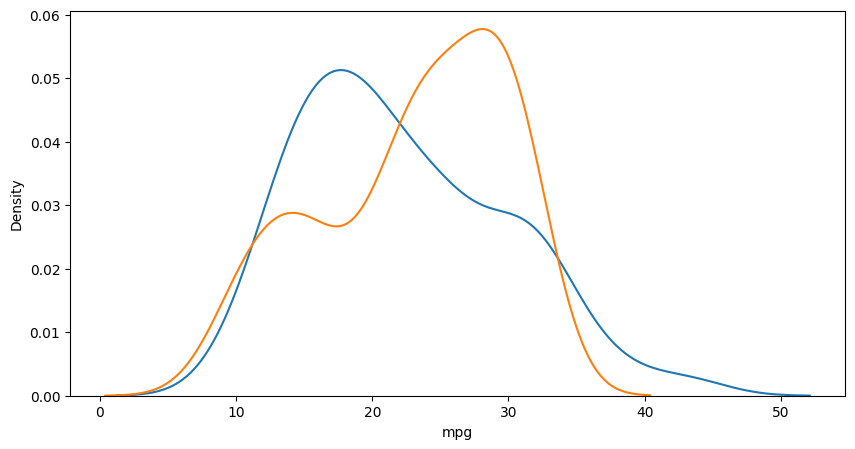

In [15]:
# train data의 산점도와 test data로 예측한 회귀선을 그래프로 출력
y_hat = lr.predict(X_test)

plt.figure(figsize=(10, 5))
ax1 = sns.distplot(y_test, hist=False, label='y_test')
ax2 = sns.distplot(y_hat, hist=False, label='y_hat', ax=ax1)
plt.show()
plt.close()

### 단순회귀분석의 결과와 비교할 때 데이터가 어느 한쪽으로 편향되는 경향은 그대로 남아있지만 그래프의 첨도가 약간 누그러짐

## 3 분류

- 예측하려는 대상의 속성을 입력받고, 목표 변수가 갖고 있는 카테고리 값 중에서 어느 한 값으로 분류하여 예측
- 훈련데이터에 목표 변수값을 함께 입력하기 때문에 지도학습유형에 속함

## 3-1 KNN

- k-Nearset-Neighbors의 약칭
- k개의 가까운 이웃이라는 뜻
- 새로운 관측값이 주어지면 기존 데이터 중에서 가장 속성이 비슷한 k개의 이웃을 먼저 찾은 후 가까운 이웃들이 갖고 있는 목표값과 같은 값으로 분류하여 예측
- k값에 따라 예측의 정확도가 달라지므로, 적절한 k값을 찾는 것이 중요

In [16]:
# 예제 7-4: KNN 분류 알고리즘

import pandas as pd
import seaborn as sns

df = sns.load_dataset('titanic')

print(df.head())
print("\n")

pd.set_option('display.max_columns', 15)
print(df.head())

   survived  pclass     sex   age  sibsp  ...  adult_male  deck  embark_town  \
0         0       3    male  22.0      1  ...        True   NaN  Southampton   
1         1       1  female  38.0      1  ...       False     C    Cherbourg   
2         1       3  female  26.0      0  ...       False   NaN  Southampton   
3         1       1  female  35.0      1  ...       False     C  Southampton   
4         0       3    male  35.0      0  ...        True   NaN  Southampton   

  alive  alone  
0    no  False  
1   yes  False  
2   yes   True  
3   yes  False  
4    no   True  

[5 rows x 15 columns]


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0 

In [17]:
# [set 2] 데이터 탐색

# 데이터의 특성과 분석 목표에 맞춰 누락 데이터를 처리

print(df.info())
print("\n")

# NaN 값이 많은 deck열 삭제, embarked의 내용이 겹치는 embark_town 열 삭제
rdf = df.drop(['deck', 'embark_town'], axis = 1)
print(rdf.columns.values)
print("\n")

# age 열에 나이 데이터가 없는 모든 행 삭제 - age 열 (891개 중 177개의 NaN값)
rdf = rdf.dropna(subset=['age'], how='any', axis=0)
print(len(rdf))
print("\n")

# embarked 열의 NaN값을 송선도시 중에서 가장 많이 출현한 값으로 치환하기
most_freq = rdf['embarked'].value_counts(dropna=True).idxmax()
print(most_freq)
print("\n")

rdf['embarked'].fillna(most_freq, inplace=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None


['survived' 'pclass' 'sex' 'age' 'sibsp' 'parch' 'fare' 'embarked' 'clas

/tmp/ipykernel_4933/4120394334.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  rdf['embarked'].fillna(most_freq, inplace=True)


In [18]:
# [step 3] 속성 선택

# sex열과 embarked 열의 범주형 데이터를 숫자형으로 변환 -> 원핫인코딩

# 분석에 활용할 열 선택
ndf = rdf[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'embarked']]
print(ndf.head())

# 원핫인코딩 - 범주형 데이터를 모형이 인식할 수 있도록 숫자형으로 변환
onehot_sex = pd.get_dummies(ndf['sex'])
ndf = pd.concat([ndf, onehot_sex], axis=1)
onehot_embarked = pd.get_dummies(ndf['embarked'], prefix='town')
ndf = pd.concat([ndf, onehot_embarked], axis=1)

ndf.drop(['sex', 'embarked'], axis=1, inplace=True)
print(ndf.head())


   survived  pclass     sex   age  sibsp  parch embarked
0         0       3    male  22.0      1      0        S
1         1       1  female  38.0      1      0        C
2         1       3  female  26.0      0      0        S
3         1       1  female  35.0      1      0        S
4         0       3    male  35.0      0      0        S
   survived  pclass   age  sibsp  parch  female   male  town_C  town_Q  town_S
0         0       3  22.0      1      0   False   True   False   False    True
1         1       1  38.0      1      0    True  False    True   False   False
2         1       3  26.0      0      0    True  False   False   False    True
3         1       1  35.0      1      0    True  False   False   False    True
4         0       3  35.0      0      0   False   True   False   False    True


In [19]:
# [step 4] 훈련/검증 데이터 분할

# 속성 선택
X = ndf[['pclass', 'age', 'sibsp', 'parch', 'female', 'male',
         'town_C', 'town_Q', 'town_S']]   # 설명 변수 X
y = ndf['survived']    # 예측 변수 Y

# 설명 변수 데이터를 정규화
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data 개수: ', X_train.shape)
print('test data 개수: ', X_test.shape)


train data 개수:  (499, 9)
test data 개수:  (215, 9)


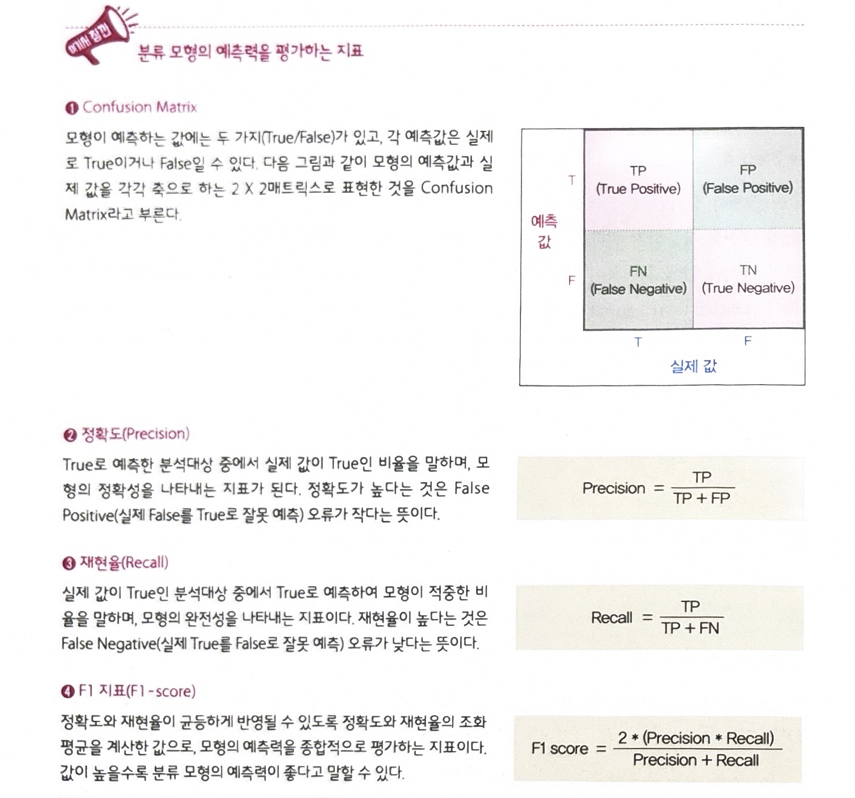

In [20]:
# [step 5] 모형 학습 및 검증

# sklearn 라이브러리에서 KNN 분류 모형 가져오기
from sklearn.neighbors import KNeighborsClassifier

# 모형 객체 생성(k=5로 설정)
knn = KNeighborsClassifier(n_neighbors=5)

# 학습 데이터를 사용하여 모형 학습
knn.fit(X_train, y_train)

# test data를 가지고 y_hat을 예측
y_hat = knn.predict(X_test)

print(y_hat[0:10])
print(y_test.values[0:10])
print("\n")

# 모형 성능 평가 - confusion Matrix 계산
from sklearn import metrics
knn_matrix = metrics.confusion_matrix(y_test, y_hat)
print(knn_matrix)
print("\n")

# 모델 성능 평가 - 평가지표 계산
knn_report = metrics.classification_report(y_test, y_hat)
print(knn_report)

[0 0 1 0 0 1 1 1 0 0]
[0 0 1 0 0 1 1 1 0 0]


[[111  14]
 [ 24  66]]


              precision    recall  f1-score   support

           0       0.82      0.89      0.85       125
           1       0.82      0.73      0.78        90

    accuracy                           0.82       215
   macro avg       0.82      0.81      0.82       215
weighted avg       0.82      0.82      0.82       215



### TP : 215명의 승객 중 미생존자를 정확히 예측. 111명
### FP : 미생존자를 생존자로 잘못 분류한 14명
### FN: 생존자를 미생존자로 잘못 분류한 24명
### TN: 생존자를 정확히 예측. 66명

## 3-2 SVM

- support vector machine의 약자, 벡터개념 가져와서 사용
- 열 벡터들이 각각 고유의 축을 갖는 벡터공간을 만드는데, 분석 대상이 되는 개별 관측값은 모든 속성에 관한 값을 해당축의 좌표로 표시하여 벡터 공간에서의 위치를 나타냄
- 속성이 2개 존재하는 데이터셋은 2차원 평면공간에 좌표로 표시, 속성이 3개면 3차원 공간에 표시, 4차 이상의 고차원 벡터공간의 좌표를 사용하는 것도 가능
- SVM 모형은 벡터 공간에 위치란 훈련 데이터의 좌표와 각 데이터가 어떤 분류값을 가져야 하는지 정답을 입력받아서 학습함

In [21]:
# 예제 7-5: SVM 모형

# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import seaborn as sns

'''
[Step 1] 데이터 준비/기본 설정
'''

# load_dataset 함수를 사용하여 데이터프레임으로 변환
df = sns.load_dataset('titanic')

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 15)

'''
[Step 2] 데이터 탐색/전처리
'''

# NaN값이 많은 deck 열 삭제, embarked와 내용이 겹치는 embark_town 열 삭제
rdf = df.drop(['deck', 'embark_town'], axis=1)

# age 열에 나이 데이터가 없는 모든 행 삭제 - age 열(891개 중 177개의 NaN값)
rdf = rdf.dropna(subset=['age'], how='any', axis=0)

# embarked 열의 NaN값을 승선도시 중에서 가장 많이 출현한 값으로 치환하기
most_freq = rdf['embarked'].value_counts(dropna=True).idxmax()
rdf['embarked'].fillna(most_freq, inplace=True)


/tmp/ipykernel_4933/3050411432.py:31: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  rdf['embarked'].fillna(most_freq, inplace=True)


In [22]:
'''
[Step 3] 분석에 사용할 속성 선택
'''

# 분석에 활용할 열(속성) 선택
ndf = rdf[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'embarked']]

# 원핫인코딩 - 범주형 데이터를 모형이 인식할 수 있도록 숫자형으로 변환
onehot_sex = pd.get_dummies(ndf['sex'])
ndf = pd.concat([ndf, onehot_sex], axis=1)

onehot_embarked = pd.get_dummies(ndf['embarked'], prefix='town')
ndf = pd.concat([ndf, onehot_embarked], axis=1)

ndf.drop(['sex', 'embarked'], axis=1, inplace=True)


In [23]:

'''
[Step 4] 데이터셋 구분 - 훈련용(train data)/검증용(test data)
'''

# 속성(변수) 선택
X = ndf[['pclass', 'age', 'sibsp', 'parch', 'female', 'male',
         'town_C', 'town_Q', 'town_S']]  # 독립 변수 X
y = ndf['survived']                      # 종속 변수 Y

# 설명 변수 데이터를 정규화(normalization)
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data 개수: ', X_train.shape)
print('test data 개수: ', X_test.shape)

# (책에서 66~71라인 생략)

train data 개수:  (499, 9)
test data 개수:  (215, 9)


In [24]:
'''
[Step 5] SVM 분류 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 SVM 분류 모형 가져오기
from sklearn import svm

# 모형 객체 생성(kernel='rbf' 적용)
svm_model = svm.SVC(kernel='rbf')   # 데이터를 벡터 공간으로 매핑하는 함수(rbf = radial basis function)

# train data를 가지고 모형 학습
svm_model.fit(X_train, y_train)

# test data를 가지고 y_hat 예측(분류)
y_hat = svm_model.predict(X_test)

print(y_hat[0:10])
print(y_test.values[0:10])

# 모형 성능 평가 - Confusion Matrix 계산
from sklearn import metrics
svm_matrix = metrics.confusion_matrix(y_test, y_hat)
print(svm_matrix)
print('\n')

# 모형 성능 평가 - 평가 지표 계산
svm_report = metrics.classification_report(y_test, y_hat)
print(svm_report)

[0 0 1 0 0 0 1 0 0 0]
[0 0 1 0 0 1 1 1 0 0]
[[120   5]
 [ 35  55]]


              precision    recall  f1-score   support

           0       0.77      0.96      0.86       125
           1       0.92      0.61      0.73        90

    accuracy                           0.81       215
   macro avg       0.85      0.79      0.80       215
weighted avg       0.83      0.81      0.81       215



### TP : 215명의 승객 중 미생존자를 정확히 예측. 120명
### FP : 미생존자를 생존자로 잘못 분류한 5명
### FN: 생존자를 미생존자로 잘못 분류한 35명
### TN: 생존자를 정확히 예측. 55명

### f1-score: 미생존자 예측 정확도 0.86, 생존자 예측 정확도 0.73

### 전반적으로 KNN 모형의 예측 능력과 큰 차이가 없음

## 3-3 Decision Tree

- 의사결정 나무라는 뜻
- 컴퓨터 알고리즘의 트리구조 사용, 각 분기점에는 분석 대상의 속성들이 위치
- 분기점마다 목표 값을 가장 잘 분류할 수 있는 속성을 찾아서 배치하고 해당 속성이 갖는 값을 이용해 새로운 가지를 만듦
- 국 분기점에서 최적의 속성을 선택할 때 해당 속성을 기준으로 분류한 값들이 구분되는 정도 측정
- 다른 종류의 값들이 섞여있는 정도를 나타내는 Entropy를 주로 활용하는데, 낮을수록 분류가 잘 된 것
- Entropy가 일정 수준 이하로 낮아질 때까지 앞의 과정 반

In [25]:
# 예제 7-6: Decision Tree 모형

# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import numpy as np

'''
[Step 1] 데이터 준비/기본 설정
'''

# Breast Cancer 데이터셋 가져오기(출처: UCI ML Repository)
uci_path = 'https://archive.ics.uci.edu/ml/machine-learning-databases/\
breast-cancer-wisconsin/breast-cancer-wisconsin.data'
df = pd.read_csv(uci_path, header=None)

# 열 이름 지정
df.columns = ['id', 'clump', 'cell_size', 'cell_shape', 'adhesion', 'epithlial',
              'bare_nuclei', 'chromatin', 'normal_nucleoli', 'mitoses', 'class']

# IPython 디스플레이 설정 - 출력할 열의 개수 한도 늘리기
pd.set_option('display.max_columns', 15)

'''
[Step 2] 데이터 탐색
'''

# 데이터 살펴보기
print(df.head())
print('\n')

# 데이터 자료형 확인
print(df.info())
print('\n')

# 데이터 통계 요약 정보 확인
print(df.describe())

# bare_nuclei 열의 자료형 변경(문자열 -> 숫자)
print(df['bare_nuclei'].unique())                               # bare_nuclei 열의 고유값 확인
print('\n')

df['bare_nuclei'].replace('?', np.nan, inplace=True)            # '?'을 np.nan으로 변경
df.dropna(subset=['bare_nuclei'], axis=0, inplace=True)         # 누락 데이터 행 삭제
df['bare_nuclei'] = df['bare_nuclei'].astype('int')             # 문자열을 정수형으로 변환

print(df.describe())                                            # 데이터 통계 요약 정보 확인


        id  clump  cell_size  cell_shape  adhesion  epithlial bare_nuclei  \
0  1000025      5          1           1         1          2           1   
1  1002945      5          4           4         5          7          10   
2  1015425      3          1           1         1          2           2   
3  1016277      6          8           8         1          3           4   
4  1017023      4          1           1         3          2           1   

   chromatin  normal_nucleoli  mitoses  class  
0          3                1        1      2  
1          3                2        1      2  
2          3                1        1      2  
3          3                7        1      2  
4          3                1        1      2  


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               699 non-null    int64 
 1   cl

/tmp/ipykernel_4933/2315930738.py:44: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bare_nuclei'].replace('?', np.nan, inplace=True)            # '?'을 np.nan으로 변경


In [26]:
'''
# [Step 3] 데이터셋 구분 - 훈련용(train data)/검증용(test data)
'''

# 속성(변수) 선택

X = df[['clump', 'cell_size', 'cell_shape', 'adhesion', 'epithlial',
        'bare_nuclei', 'chromatin', 'normal_nucleoli', 'mitoses']]  # 설명 변수 X
y = df['class']                                                     # 예측 변수 Y

# 설명 변수 데이터 정규화
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

# train data와 test data로 구분(7:3 비율)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

print('train data 개수: ', X_train.shape)
print('test data 개수: ', X_test.shape)

# (책에서 71~73라인 생략)

train data 개수:  (478, 9)
test data 개수:  (205, 9)


In [27]:

'''
[Step 4] Decision Tree 분류 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 Decision Tree 분류 모형 가져오기
from sklearn import tree

# 모형 객체 생성(criterion='entropy' 적용)
tree_model = tree.DecisionTreeClassifier(criterion='entropy', max_depth=5)

# train data를 가지고 모형 학습
tree_model.fit(X_train, y_train)

# test data를 가지고 y_hat 예측(분류)
y_hat = tree_model.predict(X_test)      # 2: benign(양성), 4: malignant(악성)

print(y_hat[0:10])
print(y_test.values[0:10])


# 모형 성능 평가 - Confusion Matrix 계산
from sklearn import metrics
tree_matrix = metrics.confusion_matrix(y_test, y_hat)
print(tree_matrix)
print('\n')

# 모형 성능 평가 - 평가 지표 계산
tree_report = metrics.classification_report(y_test, y_hat)
print(tree_report)

[4 4 4 4 4 4 2 2 4 4]
[4 4 4 4 4 4 2 2 4 4]
[[127   4]
 [  2  72]]


              precision    recall  f1-score   support

           2       0.98      0.97      0.98       131
           4       0.95      0.97      0.96        74

    accuracy                           0.97       205
   macro avg       0.97      0.97      0.97       205
weighted avg       0.97      0.97      0.97       205



### TP : 양성 정확히 예측. 127개
### FP : 양성을 악성으로 잘못 분류. 4개
### FN: 악성을 양성으로 잘못분류. 2개
### TN: 악성을 정확히 예측. 72

### f1-score: 양성종양(2) 예측 정확도 0.98, 악성종양(4) 0.96, 평균 0.97의 정확도


## 4 군집

- 데이터셋의 관측값이 갖고 있는 여러 속성을 분석하여 서로 비슷한 특징을 갖는 관측값끼리 같은 클러스터로 묶음
- 다른 클러스터 간에는 서로 완전하게 구분되는 특징을 갖기 때문에 어느 클러스터에도 속하지 못하는 관측값 존재 가능
- 이런 특성을 이용하여 특이데이터를 찾는데 활용하기도 함
- 비지도 학습유형, 관측값을 몇 개의 집단으로 나눈다는 점에서 분류알고리즘과 비슷하지만 군집분석은 정답이 없는 상태에서 데이터 자체의 유사성만을 기준으로 판단한다는 점에서 분류알고리즘과 차이가 있음

## 4-1 k-Means

- 데이터 간의 유사성을 측정하는 기준으로 각 클러스터의 중심까지의 거리를 이용함
- 벡터 공간에 위치한 어떤 데이터에 대하여 k개의 클러스터가 주어졌을 때 클러스터의 중심까지 거리가 가장 가까운 클러스터로 해당 데이터 할당
- 다른 클러스터 간에는 서로 완전하게 구분하기 위해 일정한 거리 이상 떨어져야 함
- 몇 개의 클러스터로 데이터를 구분할 것인지 결정하는 k값에 따라 모형의 성능이 달라짐
- 일반적으로 k가 클수록 모형의 정확도는 개선되지만, 너무 커지면 선택지가 너무 많아지므로 분석의 효과가 사라짐

In [28]:
# 예제 7-7: k-Means 군집 분석

# 데이터프레임 전체를 모형의 학습데이터로 사용
# 비지도 학습모형이므로 예측변수 지정할 필요 없고 속성을 모두 설명변수로 활용
# 이를 통해 서로다른 변수사이에 존재할 수 있는 데이터 값의 상대적 크기 차이에서 발생하는 오류를 제거함

# -*- coding: utf-8 -*-

### 기본 라이브러리 불러오기
import pandas as pd
import matplotlib.pyplot as plt

'''
[Step 1] 데이터 준비
'''

# Wholesale customers 데이터셋 가져오기(출처: UCI ML Repository)
uci_path = 'https://archive.ics.uci.edu/ml/machine-learning-databases/\
00292/Wholesale%20customers%20data.csv'
df = pd.read_csv(uci_path, header=0)

'''
[Step 2] 데이터 탐색
'''

# 데이터 살펴보기
print(df.head())
print('\n')

# 데이터 자료형 확인
print(df.info())
print('\n')

# 데이터 통계 요약 정보 확인
print(df.describe())


   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen

In [29]:

'''
[Step 3] 데이터 전처리
'''


# 분석에 사용할 속성 선택
X = df.iloc[:, :]
print(X[:5])
print('\n')

# 설명 변수 데이터 정규화
from sklearn import preprocessing
X = preprocessing.StandardScaler().fit(X).transform(X)

print(X[:5])


   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


[[ 1.44865163  0.59066829  0.05293319  0.52356777 -0.04111489 -0.58936716
  -0.04356873 -0.06633906]
 [ 1.44865163  0.59066829 -0.39130197  0.54445767  0.17031835 -0.27013618
   0.08640684  0.08915105]
 [ 1.44865163  0.59066829 -0.44702926  0.40853771 -0.0281571  -0.13753572
   0.13323164  2.24329255]
 [-0.69029709  0.59066829  0.10011141 -0.62401993 -0.3929769   0.6871443
  -0.49858822  0.09341105]
 [ 1.44865163  0.59066829  0.84023948 -0.05239645 -0.07935618  0.17385884
  -0.23191782  1.29934689]]


In [30]:
'''
[Step 4] k-means 군집 모형 - sklearn 사용
'''

# sklearn 라이브러리에서 cluster 군집 모형 가져오기
from sklearn import cluster

# 모형 객체 생성 - 스스로 학습하여 설정한 클러스터 개수만큼 데이터 구분
kmeans = cluster.KMeans(init='k-means++', n_clusters=5, n_init=10)

# 모형 학습
kmeans.fit(X)

# 예측(군집)
cluster_label = kmeans.labels_
print(cluster_label)
print('\n')

# 예측 결과를 데이터프레임에 추가
df['Cluster'] = cluster_label
print(df.head())


[0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 1 1 2 0 0 1 1 0 1 1 1 1 1 1 0 1
 0 0 1 1 1 0 0 0 0 0 2 0 0 1 1 0 0 1 1 2 0 1 1 0 2 0 0 1 2 1 0 1 1 1 1 1 0
 0 1 1 0 1 1 1 0 0 1 0 2 2 1 1 1 1 1 2 1 0 1 0 1 1 1 0 0 0 1 1 1 0 0 0 0 1
 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1
 1 1 1 1 1 1 1 0 0 1 0 0 0 1 1 0 0 0 0 1 1 1 0 0 1 0 1 0 1 1 1 1 1 1 1 3 1
 1 1 1 0 0 1 1 1 0 1 1 4 0 4 4 0 0 4 4 4 0 4 4 4 0 4 2 4 4 0 4 0 4 0 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 0 4 4 4 4 4 2 4 4 4 4 4 4 4
 4 4 4 4 4 0 4 0 4 0 4 4 4 4 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 4 0
 4 0 0 4 0 0 0 0 0 0 0 4 4 0 4 4 0 4 4 0 4 4 4 0 4 4 4 4 4 3 4 4 4 4 4 0 4
 2 4 0 4 4 4 4 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 1
 1 1 1 0 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1
 0 0 1 1 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1]


   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  \
0        2       3  12669  9656    

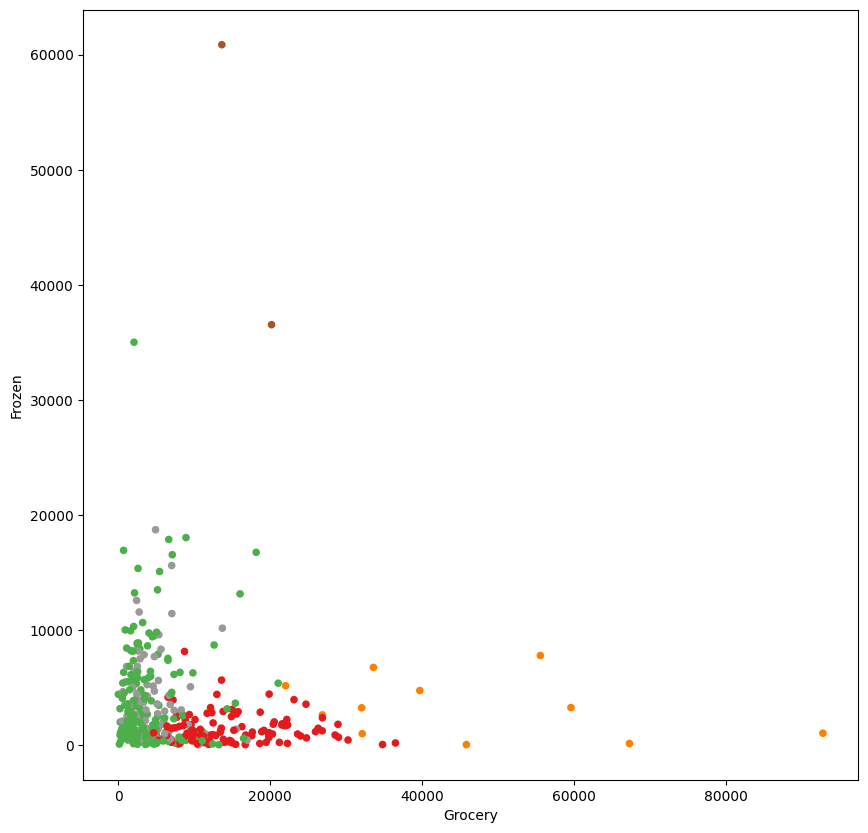

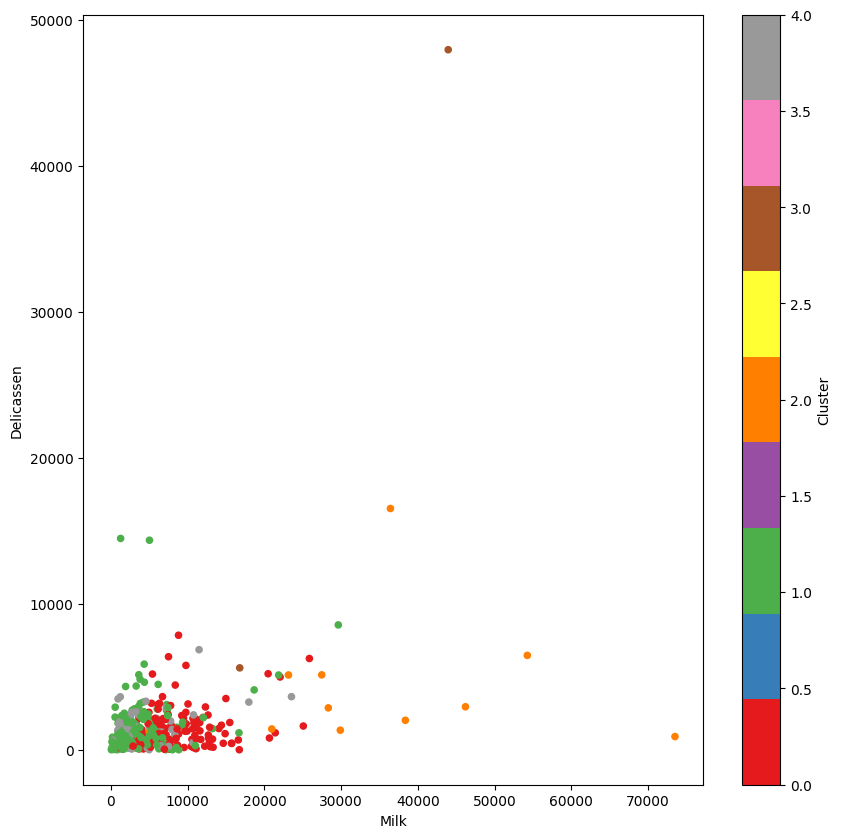

In [31]:

# 그래프로 표현 - 시각화
# 모형은 8개의 속성변수 이용하여 각 관측값들을 5개의 클러스터로 구분
# 8개의 변수를 하나의 그래프로 표현할 수 없기 떄문에 2개의 변수를 선택해 관측값의 분포 그려봄
df.plot(kind='scatter', x='Grocery', y='Frozen', c='Cluster', cmap='Set1',
        colorbar=False, figsize=(10, 10))
df.plot(kind='scatter', x='Milk', y='Delicassen', c='Cluster', cmap='Set1',
        colorbar=True, figsize=(10, 10))
plt.show()
plt.close()


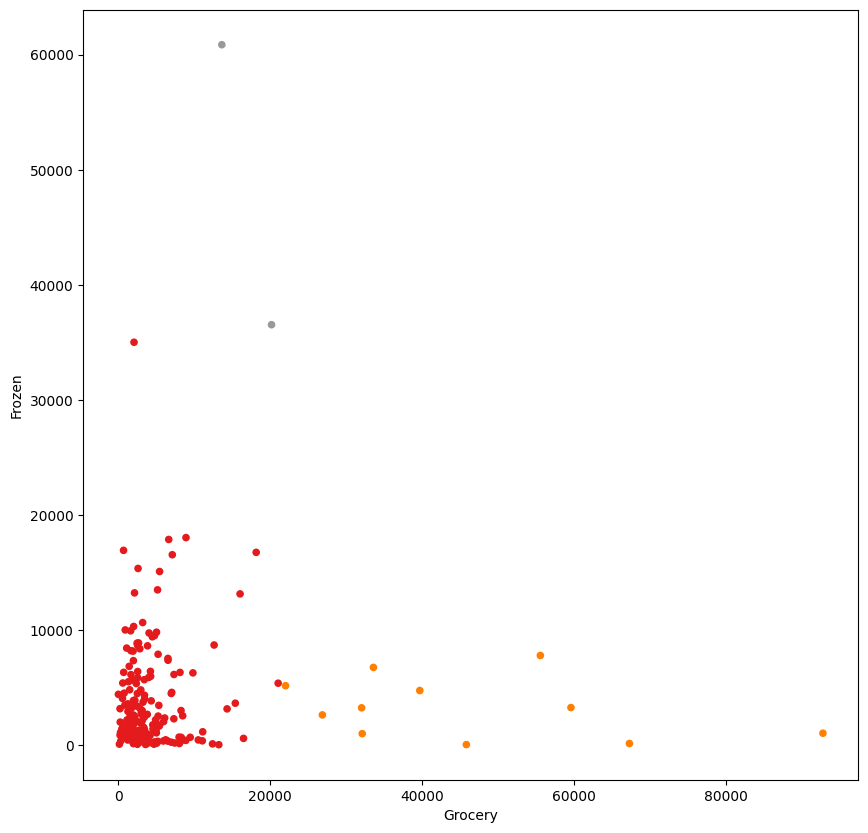

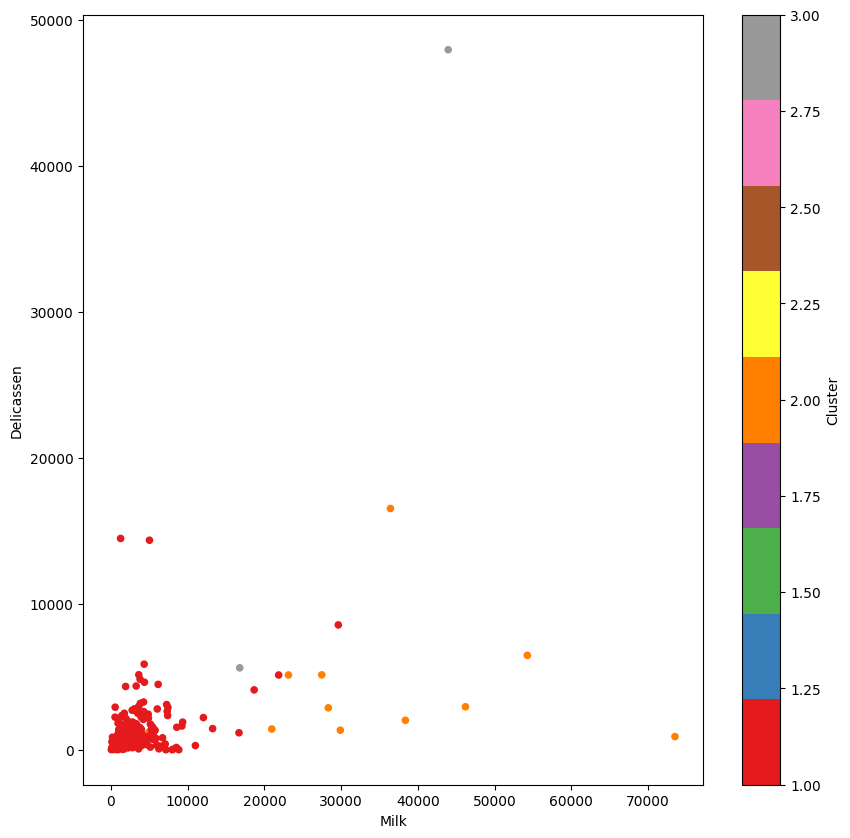

In [32]:
# 큰 값으로 구성된 클러스터(0, 4) 제외 - 값이 몰려 있는 구간을 자세하게 분석
mask = (df['Cluster'] == 0) | (df['Cluster'] == 4)
ndf = df[~mask]

ndf.plot(kind='scatter', x='Grocery', y='Frozen', c='Cluster', cmap='Set1',
         colorbar=False, figsize=(10, 10))
ndf.plot(kind='scatter', x='Milk', y='Delicassen', c='Cluster', cmap='Set1',
         colorbar=True, figsize=(10, 10))
plt.show()
plt.close()

## DBSCAN

-Density-Based Spatial Clustering of Applications with Noise
- 데이터가 위치하고 있는 공간 밀집도를 기준으로 클러스터 구분
- 자기를 중심으로 반지름 r공간에 최소 m개의 포인트가 존재하는 점을 코어포인트라고 부른다
- 코어포인트는 아니지만 반지름 r안에 다른 코어 포인트가 있을 경우 경계 포인트라고 한다
- 코어포인트와 경계포인트 모두에 속하지 않는 점을 nosie라고 부른다
- 하나의 클러스터는 반지름 r 안에 서로 위치하는 모든 코어 포인트를 포함하는 방식으로 구성
- 각 코어포인트 주위에 있는 경계포인트를 포함
- 서로 밀접한 데이터끼리 하나의 클러스터를 구성, 어느 클러스터에도 속하지 않는 점들은 noise로 남게된다

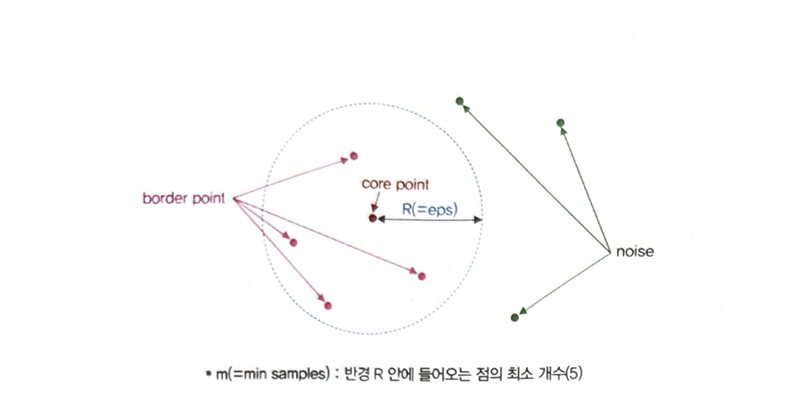

In [47]:
# 예제 7-8: DBSCAN

from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# [Step 1] 서울시내 중학교 진학률 데이터셋

# 1. 구글 드라이브 마운트
drive.mount('/content/drive')

# 2. CSV 파일 경로
file_path = "/content/drive/MyDrive/[980-8]예제파일_파이썬 머신러닝 판다스 데이터 분석(개정판)/pandas-data-analysis-main/part7/data/middle_shcool_graduates_report.xlsx"

# 3. 데이터 불러오기
df = pd.read_excel(file_path, header=0)

# 타일 설정 (Esri 지형도 - Stamen Terrain이랑 느낌 비슷함)
TILES = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}'
ATTR = 'Esri'

mschool_map = folium.Map(location=[37.55, 126.98], tiles=TILES, attr=ATTR,
                         zoom_start=12)


# IPython Console 디스플레이 옵션 설정하기
pd.set_option('display.width', None)                     # 출력 화면의 너비
pd.set_option('display.max_rows', 100)                   # 출력할 행의 개수 한도
pd.set_option('display.max_columns', 10)                 # 출력할 열의 개수 한도
pd.set_option('display.max_colwidth', 20)                # 출력할 열의 너비
pd.set_option('display.unicode.east_asian_width', True)  # 유니코드 사용 너비 조정

# 열 이름 배열 출력
print(df.columns.values)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['지역' '학교명' '코드' '유형' '주야' '남학생수' '여학생수' '일반고' '특성화고' '과학고' '외고_국제고'
 '예고_체고' '마이스터고' '자사고' '자공고' '기타진학' '취업' '미상' '위도' '경도']


In [53]:
'''
[Step 2] 데이터 탐색
'''

# 데이터 살펴보기
print(df.head())
print('\n')

# 데이터 자료형 확인
print(df.info())
print('\n')

# 데이터 통계 요약 정보 확인
print(df.describe())

# (책에서 42~43라인 생략)

# 지도에 위치 표시
mschool_map = folium.Map(location=[37.55, 126.98], tiles='CartoDB positron',
                         zoom_start=12)

# 타일 설정 (Esri 지형도 - Stamen Terrain이랑 느낌 비슷함)
TILES = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}'
ATTR = 'Esri'

mschool_map = folium.Map(location=[37.55, 126.98], tiles=TILES, attr=ATTR,
                         zoom_start=12)


# 중학교 위치 정보를 CircleMarker로 표시
for name, lat, lng in zip(df.학교명, df.위도, df.경도):
    folium.CircleMarker([lat, lng],
                        radius=5,                # 원의 반지름
                        color='brown',           # 원의 둘레 색상
                        fill=True,
                        fill_color='coral',      # 원을 채우는 색
                        fill_opacity=0.7,        # 투명도
                        popup=name
    ).add_to(mschool_map)

# 지도를 html 파일로 저장하기
mschool_map.save('/content/drive/MyDrive/[980-8]예제파일_파이썬 머신러닝 판다스 데이터 분석(개정판)/pandas-data-analysis-main/part7/seoul_mschool_location.html')


     지역                               학교명  코드  유형  주야  ...  code  \
0  성북구  서울대학교사범대학부설중학교.....       3  국립  주간  ...     0   
1  종로구  서울대학교사범대학부설여자중학교...     3  국립  주간  ...     0   
2  강남구           개원중학교                     3  공립  주간  ...     0   
3  강남구           개포중학교                     3  공립  주간  ...     0   
4  서초구           경원중학교                     3  공립  주간  ...     0   

   type  day  Cluster  Cluster2  
0     1    0       -1        -1  
1     1    0       -1        -1  
2     0    0       -1        -1  
3     0    0       -1        -1  
4     0    0       -1        -1  

[5 rows x 26 columns]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 26 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   지역        415 non-null    object 
 1   학교명       415 non-null    object 
 2   코드        415 non-null    int64  
 3   유형        415 non-null    object 
 4   주야        415 non-null    object 
 5   남학생수

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


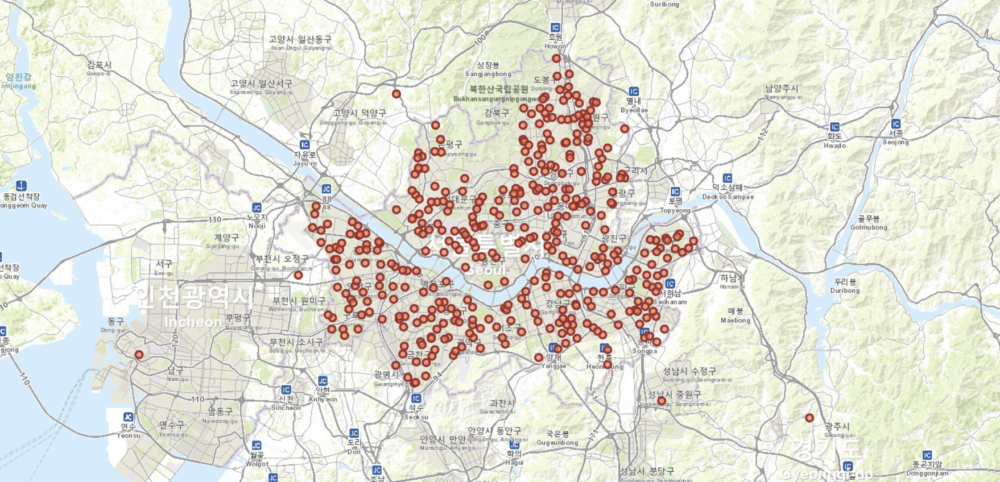

In [49]:

'''
[Step 3] 데이터 전처리
'''

# 원핫인코딩(더미 변수)
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()    # label encoder 생성
onehot_encoder = preprocessing.OneHotEncoder()  # one hot encoder 생성

onehot_location = label_encoder.fit_transform(df['지역'])
onehot_code = label_encoder.fit_transform(df['코드'])
onehot_type = label_encoder.fit_transform(df['유형'])
onehot_day = label_encoder.fit_transform(df['주야'])

df['location'] = onehot_location
df['code'] = onehot_code
df['type'] = onehot_type
df['day'] = onehot_day

print(df.head())

# (책에서 84~86라인 생략)

     지역                               학교명  코드  유형  주야  ...  \
0  성북구  서울대학교사범대학부설중학교.....       3  국립  주간  ...   
1  종로구  서울대학교사범대학부설여자중학교...     3  국립  주간  ...   
2  강남구           개원중학교                     3  공립  주간  ...   
3  강남구           개포중학교                     3  공립  주간  ...   
4  서초구           경원중학교                     3  공립  주간  ...   

         경도  location  code  type  day  
0  127.038909        16     0     1    0  
1  127.003857        22     0     1    0  
2  127.071744         0     0     0    0  
3  127.062201         0     0     0    0  
4  127.008900        14     0     0    0  

[5 rows x 24 columns]


In [50]:
'''
[Step 4] DBSCAN 군집 모형 - sklearn 사용 / 모형학습 및 검증
'''

# sklearn 라이브러리에서 cluster 군집 모형 가져오기
from sklearn import cluster

# 분석에 사용할 속성 선택(과학고, 외고국제고, 자사고 진학률)
columns_list = [9, 10, 13]
X = df.iloc[:, columns_list]
print(X[:5])
print('\n')

# 설명 변수 데이터 정규화
X = preprocessing.StandardScaler().fit(X).transform(X)

# DBSCAN 모형 객체 생성
dbm = cluster.DBSCAN(eps=0.2, min_samples=5) # 반지름 R=eps, 최소포인트개수 mis_samples

# 모형 학습
dbm.fit(X)

# 예측(군집)
cluster_label = dbm.labels_
print(cluster_label)
print('\n')

# 예측 결과를 데이터프레임에 추가
df['Cluster'] = cluster_label
print(df.head())



   과학고  외고_국제고  자사고
0   0.018        0.007   0.227
1   0.000        0.035   0.043
2   0.009        0.012   0.090
3   0.013        0.013   0.065
4   0.007        0.010   0.282


[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  0 -1 -1 -1 -1 -1 -1  2 -1  0 -1
 -1 -1 -1 -1  0 -1 -1 -1 -1 -1  0  3 -1 -1 -1 -1 -1 -1 -1  0 -1 -1  1  0
 -1 -1 -1  0 -1 -1 -1 -1  0 -1  0  0 -1 -1  0 -1 -1 -1  0  0 -1 -1  0 -1
 -1 -1  0 -1 -1 -1  0  2  0  0  0  0  0 -1 -1 -1  0 -1  0 -1 -1  0 -1  0
 -1  0  0 -1 -1 -1 -1  1  0 -1  0  0 -1 -1 -1  0 -1 -1 -1 -1 -1  0  1 -1
 -1  0  2  0 -1 -1  1 -1 -1 -1  0  0  0 -1 -1  0 -1 -1 -1  0  0 -1 -1 -1
 -1  0 -1 -1 -1  0 -1 -1 -1  0 -1  0  0 -1 -1 -1 -1 -1  0 -1  0  0 -1 -1
 -1 -1 -1  0 -1 -1 -1  1  0  3  1 -1  0  0 -1  0 -1 -1  0  0  2 -1 -1  3
  0  0 -1 -1 -1 -1  0 -1  0  0 -1  0  0  0 -1 -1  0 -1 -1 -1 -1 -1  2  0
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  0 -1 -1 -1  0 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1  0 -1 -1 -1  0  0 -1 -1  0 -1  3  0  2 -1 -1
 -1 -1  0 -1 -1 -1  

In [54]:
# 클러스터 값으로 그룹화하고 그룹별로 내용 출력(첫 5행만 출력)

# O: 외고, 자사고 합격률 높지만 과학고 합격자 없음
# 1: 자사고 합격자만 존재
# 2: 자사고 합격률이 매우 높으면서 과학고, 외고 합격자 일부 존재
# 3: 과학고 합격자 없이 외고와 자사고 합격자, 0에 비해 외고 합격률 현저히 낮음
grouped_cols = [0, 1, 3] + columns_list
grouped = df.groupby('Cluster')
for key, group in grouped:
    print('* key :', key)
    print('* number :', len(group))
    print(group.iloc[:, grouped_cols].head())
    print('\n')

# 그래프로 표현 - 시각화
colors = {-1: 'gray', 0: 'coral', 1: 'blue', 2: 'green', 3: 'red', 4: 'purple',
          5: 'orange', 6: 'brown', 7: 'brick', 8: 'yellow', 9: 'magenta', 10: 'cyan'}


# 타일 설정 (Esri 지형도 - Stamen Terrain이랑 느낌 비슷함)
TILES = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}'
ATTR = 'Esri'

cluster_map = folium.Map(location=[37.55, 126.98], tiles=TILES, attr=ATTR,
                         zoom_start=12)

for name, lat, lng, clus in zip(df.학교명, df.위도, df.경도, df.Cluster):
    folium.CircleMarker([lat, lng],
                        radius=5,                   # 원의 반지름
                        color=colors[clus],         # 원의 둘레 색상
                        fill=True,
                        fill_color=colors[clus],    # 원을 채우는 색
                        fill_opacity=0.7,           # 투명도
                        popup=name
    ).add_to(cluster_map)

# 지도를 html 파일로 저장하기
# 지도를 html 파일로 저장하기
cluster_map.save(
    '/content/drive/MyDrive/[980-8]예제파일_파이썬 머신러닝 판다스 데이터 분석(개정판)/pandas-data-analysis-main/part7/seoul_mschool_cluster.html'
)

* key : -1
* number : 255
     지역                               학교명  유형  과학고  외고_국제고  \
0  성북구  서울대학교사범대학부설중학교.....    국립   0.018        0.007   
1  종로구  서울대학교사범대학부설여자중학교...  국립   0.000        0.035   
2  강남구           개원중학교                  공립   0.009        0.012   
3  강남구           개포중학교                  공립   0.013        0.013   
4  서초구           경원중학교                  공립   0.007        0.010   

   자사고  
0   0.227  
1   0.043  
2   0.090  
3   0.065  
4   0.282  


* key : 0
* number : 102
      지역          학교명  유형  과학고  외고_국제고  자사고
13  서초구  동덕여자중학교  사립     0.0        0.022   0.038
22  강남구      수서중학교  공립     0.0        0.019   0.044
28  서초구      언남중학교  공립     0.0        0.015   0.050
34  강남구      은성중학교  사립     0.0        0.016   0.065
43  송파구      거원중학교  공립     0.0        0.021   0.054


* key : 1
* number : 45
         지역          학교명  유형  과학고  외고_국제고  자사고
46     강동구      동신중학교  사립     0.0          0.0   0.044
103    양천구      신원중학교  공립     0.0          0.0   0.006
118    구로구     

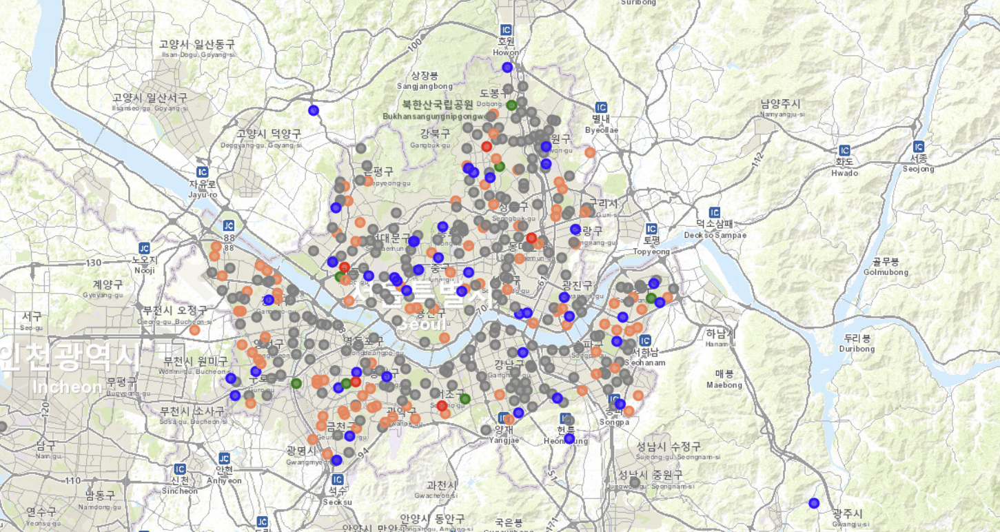

In [55]:
# X2 데이터셋에 대하여 위의 과정을 반복(과학고, 외고국제고, 자사고 진학률 + 유형)

# 변수를 늘리면(X2) 공간이 넓어져서 점들이 듬성듬성해지니까 noise가 늘어나고. 반대로 줄이면(X3) 점들이 빽빽해져서 noise가 확 줄어듦. -> 어떤 변수를 넣느냐, 그리고 eps와 min_samples를 어떻게 잡느냐에 따라 결과가 크게 달라진다

columns_list2 = [9, 10, 13, 22]
X2 = df.iloc[:, columns_list2]
print(X2[:5])
print('\n')

X2 = preprocessing.StandardScaler().fit(X2).transform(X2)
dbm2 = cluster.DBSCAN(eps=0.2, min_samples=5)
dbm2.fit(X2)
df['Cluster2'] = dbm2.labels_

grouped2_cols = [0, 1, 3] + columns_list2
grouped2 = df.groupby('Cluster2')
for key, group in grouped2:
    print('* key :', key)
    print('* number :', len(group))
    print(group.iloc[:, grouped2_cols].head())
    print('\n')

# 타일 설정 (Esri 지형도 - Stamen Terrain이랑 느낌 비슷함)
TILES = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}'
ATTR = 'Esri'

cluster2_map = folium.Map(location=[37.55, 126.98], tiles=TILES, attr=ATTR,
                         zoom_start=12)


for name, lat, lng, clus in zip(df.학교명, df.위도, df.경도, df.Cluster2):
    folium.CircleMarker([lat, lng],
                        radius=5,                   # 원의 반지름
                        color=colors[clus],         # 원의 둘레 색상
                        fill=True,
                        fill_color=colors[clus],    # 원을 채우는 색
                        fill_opacity=0.7,           # 투명도
                        popup=name
    ).add_to(cluster2_map)

# 지도를 html 파일로 저장하기
cluster2_map.save('/content/drive/MyDrive/[980-8]예제파일_파이썬 머신러닝 판다스 데이터 분석(개정판)/pandas-data-analysis-main/part7/seoul_mschool_cluster2.html')


   과학고  외고_국제고  자사고  type
0   0.018        0.007   0.227     1
1   0.000        0.035   0.043     1
2   0.009        0.012   0.090     0
3   0.013        0.013   0.065     0
4   0.007        0.010   0.282     0


* key : -1
* number : 281
     지역                               학교명  유형  과학고  외고_국제고  \
0  성북구  서울대학교사범대학부설중학교.....    국립   0.018        0.007   
1  종로구  서울대학교사범대학부설여자중학교...  국립   0.000        0.035   
2  강남구           개원중학교                  공립   0.009        0.012   
3  강남구           개포중학교                  공립   0.013        0.013   
4  서초구           경원중학교                  공립   0.007        0.010   

   자사고  type  
0   0.227     1  
1   0.043     1  
2   0.090     0  
3   0.065     0  
4   0.282     0  


* key : 0
* number : 8
       지역      학교명  유형  과학고  외고_국제고  자사고  type
22   강남구  수서중학교  공립     0.0        0.019   0.044     0
43   송파구  거원중학교  공립     0.0        0.021   0.054     0
51   송파구  방이중학교  공립     0.0        0.021   0.068     0
93   강서구  방원중학교  공립     0.0        0.019 

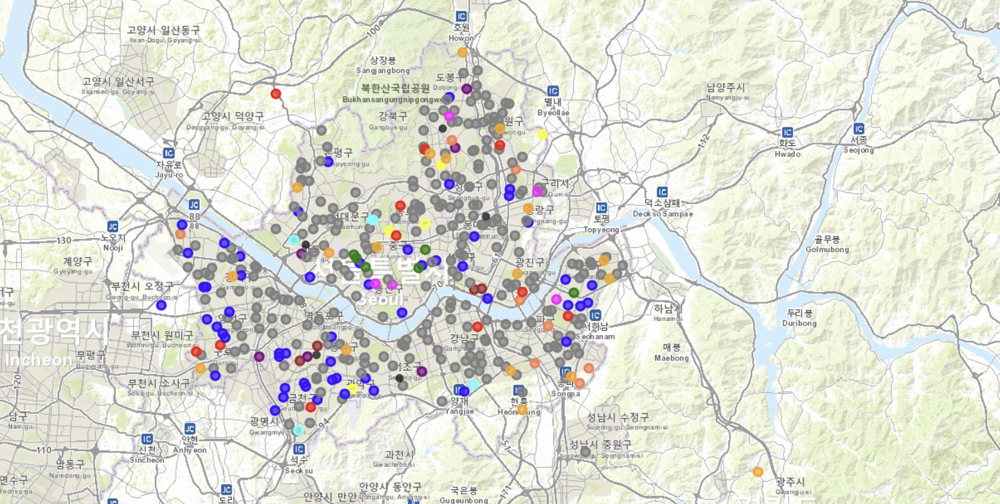